In [1]:
%load_ext autoreload
%autoreload 2

# Classification models

Here, we run all our classification models so that we can compare them side-by-side. We compare a dummy model and simple logistic model to logistic models with two regularization strategies (L1 and L2), a decision tree model, a random forest model, and a boosted regression tree model. Hyperparameters are tuned using either GridSearchCV or RandomizedSearchCV. We also run our models on several different splits to understand the limits of our models.

In [2]:
'''Import all relevant modules here and define root directory.'''

# Define root directory
import sys
from pathlib import Path

cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT))

# Modules imported form outside
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.calibration import calibration_curve

# Modules internal to this project
from src.models.evaluate import CONFIGS, run_models, tuned, all_features, linear_features, load_predictions
from src.evaluation.results_log import load_runs, summarize

The following cell is used to set up necessary variables and define the parameter grids used for hyperparameter tuning.

In [3]:
BRIER = "neg_brier_score"                       # tune for well-calibrated probabilities
C_VALUES = np.logspace(-4, 2, 13)
TREE_DEPTHS = [2, 3, 4, 5, 6, 8, 10, 15]
RF_GRID = {
    "max_depth": [6, 8, 11, 15, None], 
    "max_features": ["sqrt", 0.3, 0.5], 
    "min_samples_leaf": [1, 5, 20]
}
BRT_GRID = {
    "learning_rate": [0.03, 0.05], 
    "n_estimators": [20, 35, 50, 75, 100], 
    "max_depth": [2, 3, 4], 
    "min_child_weight": [5, 20, 50], 
    "subsample": [0.5, 0.7]
}

In [4]:
def linear_pipe(model):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)

The following cell contains our list of classification models.

In [5]:
CLASSIFICATION_MODELS = {
    "Dummy (prior)": ("Team", lambda: DummyClassifier(strategy="prior"), all_features),
    "Logistic": ("Andrea", lambda: linear_pipe(LogisticRegression(C=np.inf, max_iter=5000)), linear_features),
    "Logistic L2": ("Andrea", lambda: tuned(linear_pipe(LogisticRegression(max_iter=5000)), {"logisticregression__C": C_VALUES}, BRIER), linear_features),
    "Logistic L1": ("Andrea", lambda: tuned(linear_pipe(LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=5000)), {"logisticregression__C": C_VALUES}, BRIER), linear_features),
    "Decision tree": ("Gavin", lambda: tuned(DecisionTreeClassifier(min_samples_leaf=20, random_state=0), {"max_depth": TREE_DEPTHS}, BRIER), all_features),
    "Random forest": ("Charlsey", lambda: tuned(RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=1), RF_GRID, BRIER, n_iter=10), all_features),
    "XGBoost BRT": ("Karuna", lambda: tuned(xgboost.XGBClassifier(objective="binary:logistic", max_bin=64, random_state=0, n_jobs=1), BRT_GRID, BRIER, n_iter=20), all_features),
}

In [6]:
'''Run all models on each of the splits/configurations. The last fold in each split is set aside in each case for final validation.'''

RUN_MODELS = False    # True: refit every model (about 20 minutes per notebook); False: load the saved predictions

if RUN_MODELS:
    devs, oof = run_models(CLASSIFICATION_MODELS, task="classification")
else:
    devs, oof = load_predictions("classification")

We now compare model performances across all configurations.

In [7]:
clf_runs = load_runs().query("task == 'classification'")
for metric in ["brier_skill", "auc"]:
    display(clf_runs.groupby(["model", "split", "use_subbasin"])[metric].mean().unstack(["split", "use_subbasin"]).round(3))

split           10km        10km_subbasin 5km_subbasin 7.5km_subbasin
use_subbasin   False  True          True         True           True 
model                                                                
Decision tree  0.103  0.188         0.211        0.180          0.197
Dummy (prior)  0.000  0.000         0.000        0.000          0.000
Logistic       0.091  0.150         0.225        0.218          0.197
Logistic L1    0.122  0.191         0.228        0.219          0.228
Logistic L2    0.135  0.195         0.206        0.216          0.220
Random forest  0.225  0.242         0.291        0.265          0.254
XGBoost BRT    0.216  0.216         0.272        0.246          0.244

split           10km        10km_subbasin 5km_subbasin 7.5km_subbasin
use_subbasin   False  True          True         True           True 
model                                                                
Decision tree  0.713  0.762         0.765        0.771          0.743
Dummy (prior)  0.500  0.500         0.500        0.500          0.500
Logistic       0.735  0.771         0.800        0.798          0.769
Logistic L1    0.734  0.787         0.798        0.795          0.786
Logistic L2    0.738  0.787         0.791        0.792          0.778
Random forest  0.791  0.801         0.827        0.826          0.796
XGBoost BRT    0.791  0.794         0.809        0.811          0.790

See model performance on the main configuration: 10km grid cells stratified along subbasin, with subbasin data included as a feature. We consider thresholds of 0.4, 0.45, and 0.5.

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, confusion_matrix, average_precision_score, precision_score, recall_score, f1_score, balanced_accuracy_score, brier_score_loss

CONFIG = ("10km_subbasin", True)      # which configuration to plot
THRESHOLDS = [0.25, 0.3, 0.35, 0.4, 0.45, 0.5]         # probabilities at or above which a sample is called an exceedance
DARKEST, LIGHTEST = 0.0, 0.6          # 0 = black, 1 = white; 0.6 is a medium gray
n = len(THRESHOLDS)
THRESHOLD_COLORS = {t: str(DARKEST + (LIGHTEST - DARKEST) * i / (n - 1)) for i, t in enumerate(THRESHOLDS)}
MARKERS = ["D", "v", "P", "o", "s", "^", "X", "*"]
THRESHOLD_MARKERS = {t: MARKERS[i] for i, t in enumerate(THRESHOLDS)}
FIGURES = ROOT / "results" / "classification"
FIGURES.mkdir(parents=True, exist_ok=True)

dev = devs[CONFIG]
y_true = dev["exceeds"].to_numpy()
folds = dev["fold"].to_numpy()
prevalence = y_true.mean()
probs = {name: oof[(name, *CONFIG)] for name in CLASSIFICATION_MODELS if not name.startswith("Dummy")}
TAG = f"{CONFIG[0]}, subbasin features={CONFIG[1]}"


def panels(n, ncols=3, width=4.5, height=3.8):
    """A grid with one panel per model (or metric); unused panels are hidden."""
    nrows = -(-n // ncols)                            # ceiling division
    fig, axs = plt.subplots(nrows, ncols, figsize=(width * ncols, height * nrows), squeeze=False)
    axs = axs.ravel()
    for ax in axs[n:]:
        ax.set_axis_off()
    return fig, axs


def save(fig, name):
    fig.savefig(FIGURES / f"{name}_{CONFIG[0]}_subbasin{int(CONFIG[1])}.png", dpi=150, bbox_inches="tight")


def threshold_counts(prob, threshold):
    """Confusion-matrix counts and rates when samples with prob >= threshold are called exceedances."""
    predicted = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "missed_exceedances": fn, 
        "false_alarms": fp,
        "recall": tp / (tp + fn),
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "false_positive_rate": fp / (fp + tn),
        "share_flagged": (tp + fp) / len(y_true)
    }


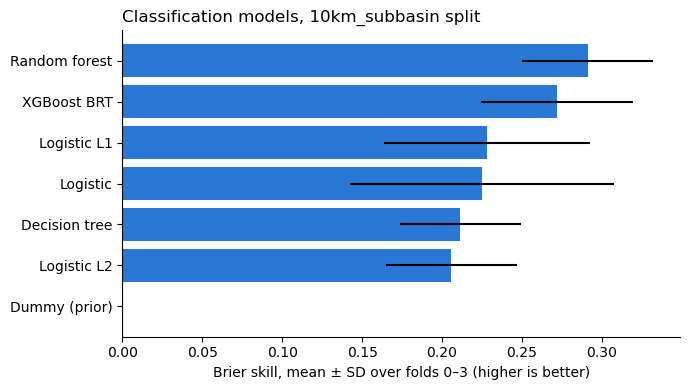

In [9]:
main = clf_runs[(clf_runs["split"] == CONFIG[0]) & (clf_runs["use_subbasin"] == CONFIG[1])]
by_model = main.groupby("model")["brier_skill"].agg(["mean", "std"]).sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(by_model.index, by_model["mean"], xerr=by_model["std"], color="#2a78d6")
ax.invert_yaxis()                                   # best model on top
ax.axvline(0, color="gray", linewidth=0.8)          # 0 = no better than the training exceedance rate
ax.set_xlabel("Brier skill, mean ± SD over folds 0–3 (higher is better)")
ax.set_title(f"Classification models, {CONFIG[0]} split", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
save(fig, "model_comparison")
plt.show()


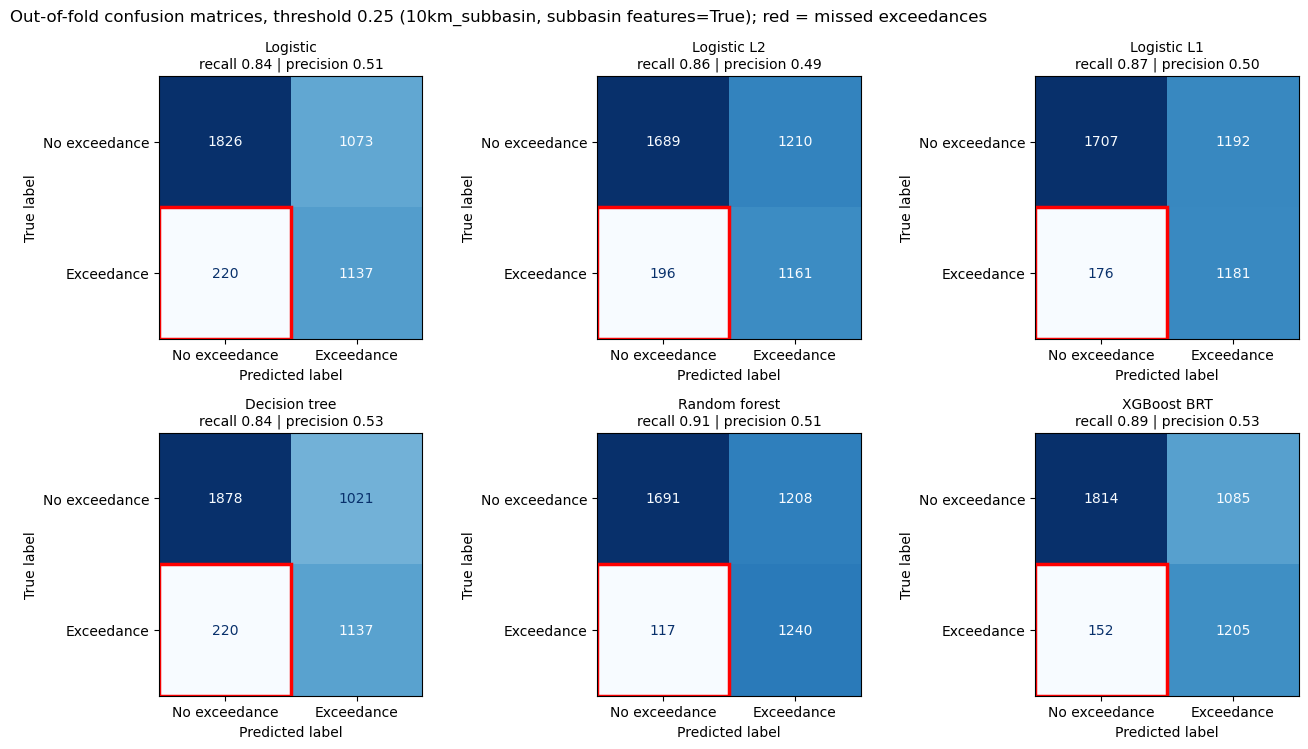

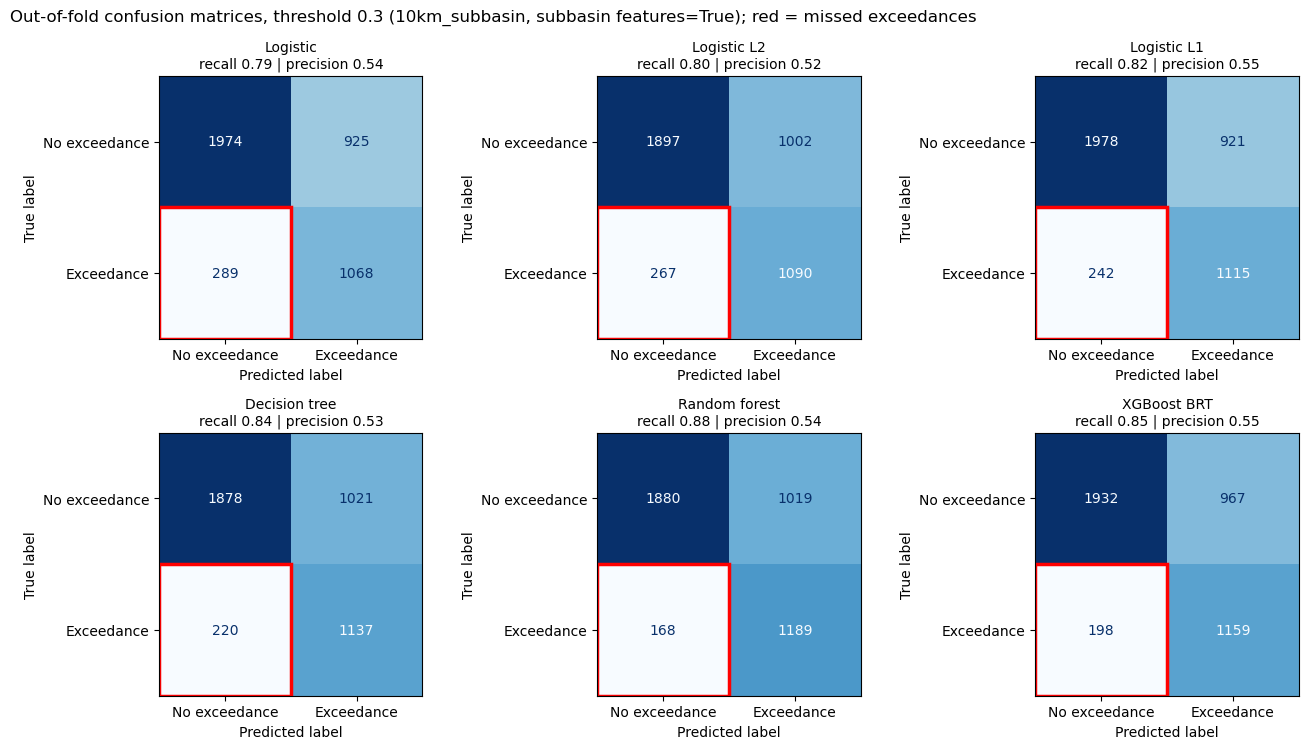

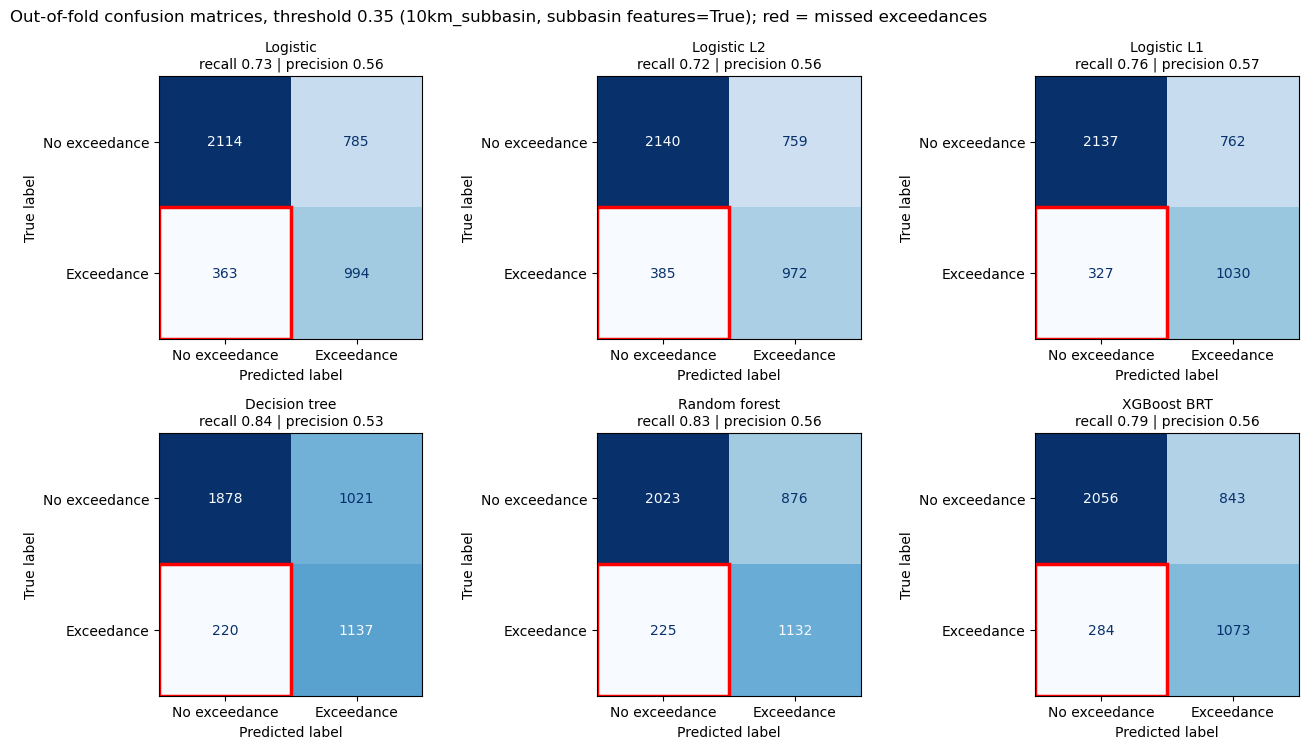

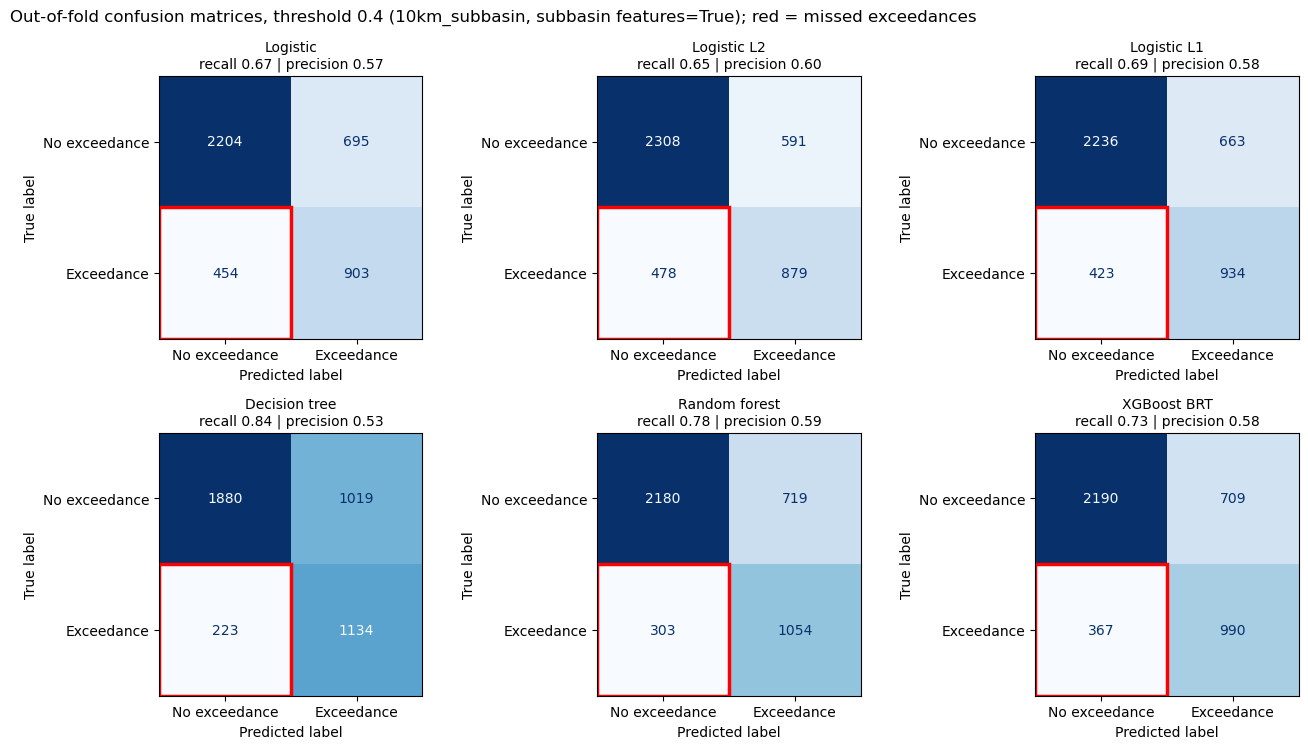

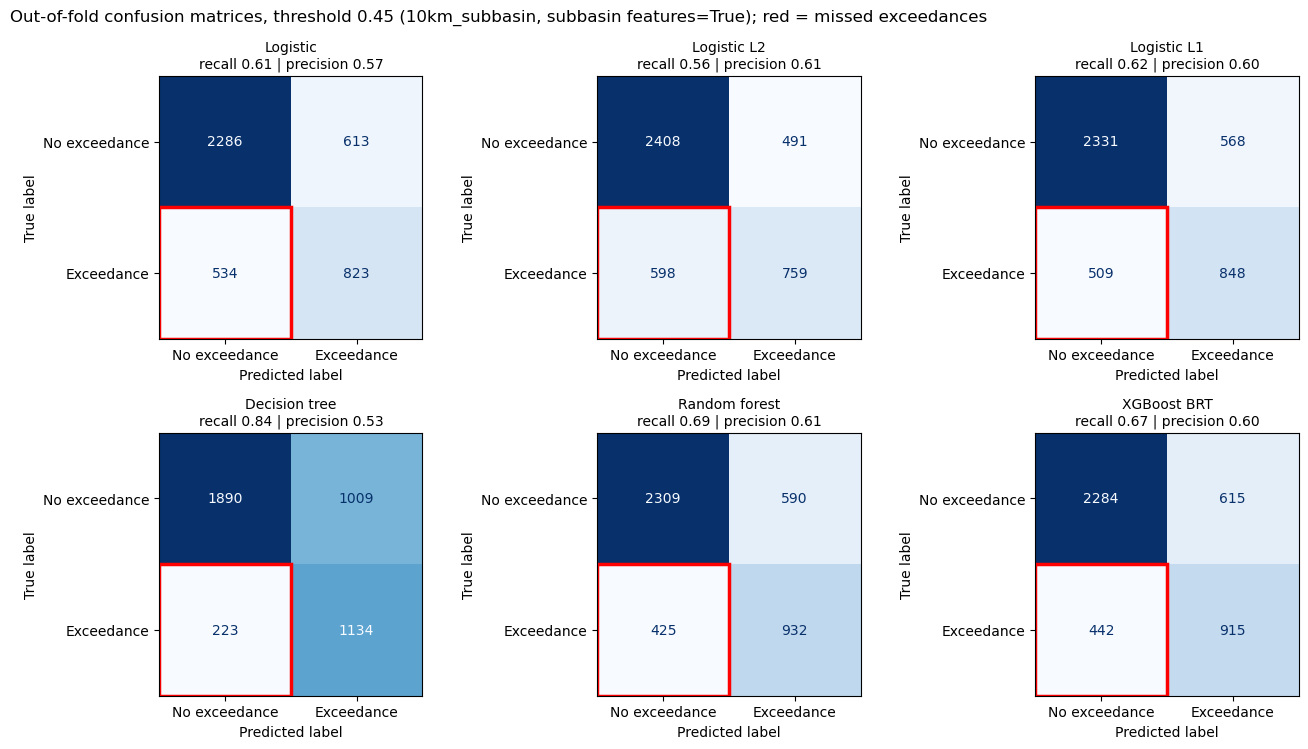

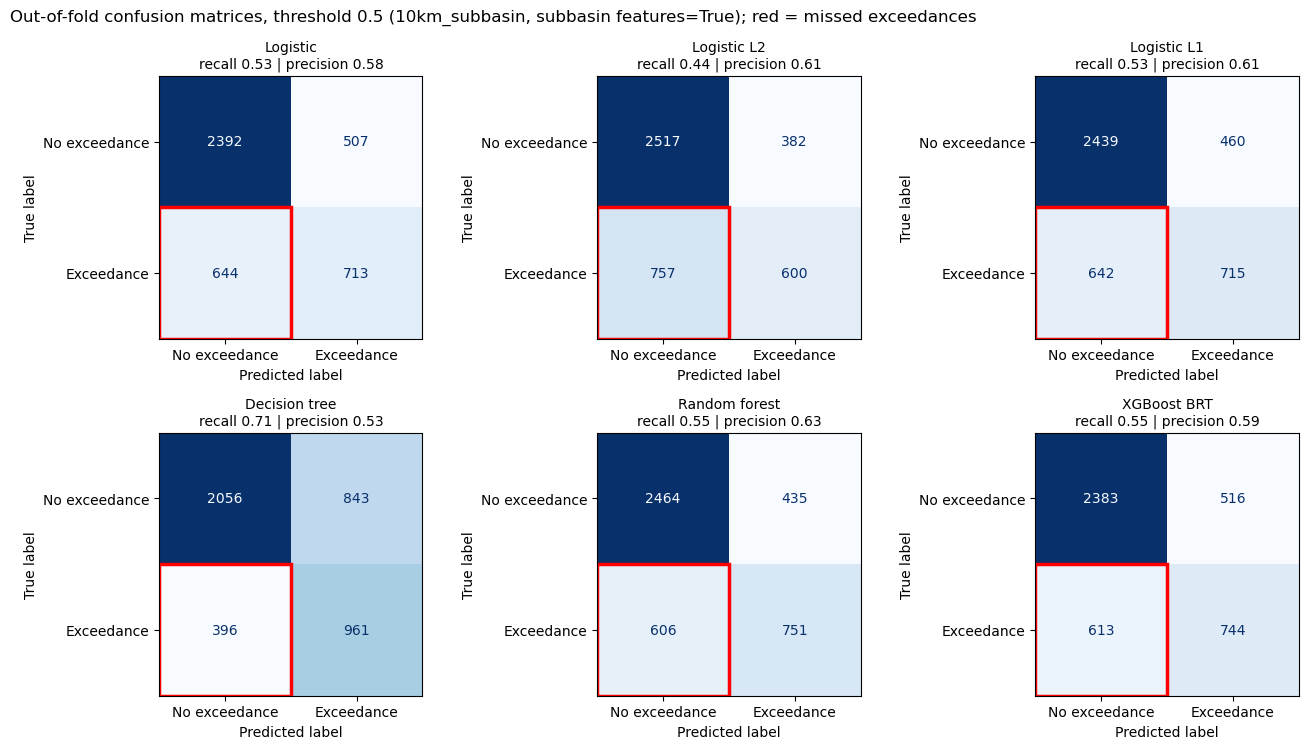

In [10]:
for threshold in THRESHOLDS:
    fig, axs = panels(len(probs))
    for ax, (name, prob) in zip(axs, probs.items()):
        predicted = (prob >= threshold).astype(int)
        ConfusionMatrixDisplay.from_predictions(y_true, predicted, labels=[0, 1], display_labels=["No exceedance", "Exceedance"], cmap="Blues", values_format="d", colorbar=False, ax=ax)
        ax.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1, fill=False, edgecolor="red", linewidth=2.5))
        counts = threshold_counts(prob, threshold)
        ax.set_title(f"{name}\nrecall {counts['recall']:.2f} | precision {counts['precision']:.2f}", fontsize=10)
    fig.suptitle(f"Out-of-fold confusion matrices, threshold {threshold} ({TAG}); red = missed exceedances", x=0.01, ha="left")
    plt.tight_layout()
    save(fig, f"confusion_matrices_t{threshold}")
    plt.show()


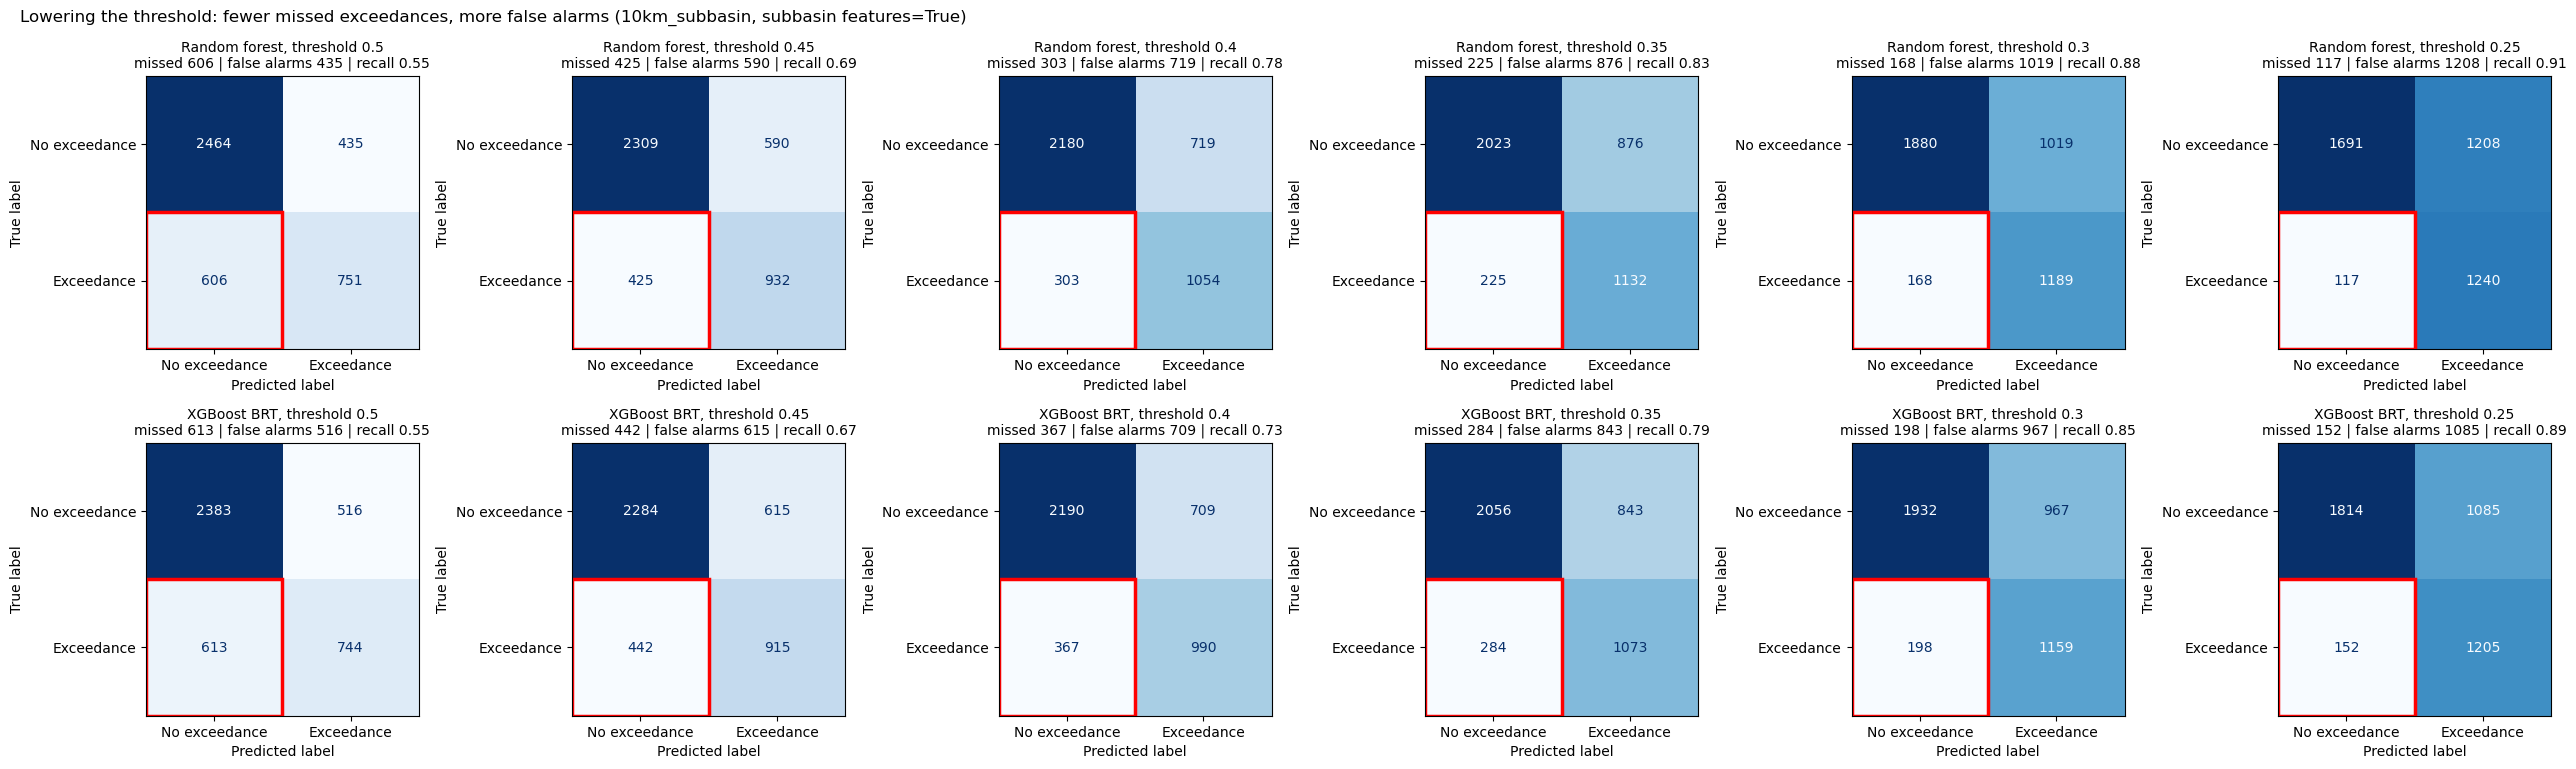

In [11]:
SHOW_MODELS = ["Random forest", "XGBoost BRT"]
fig, axs = plt.subplots(len(SHOW_MODELS), len(THRESHOLDS), squeeze=False, figsize=(4.3 * len(THRESHOLDS), 3.9 * len(SHOW_MODELS)))
for row, name in zip(axs, SHOW_MODELS):
    for ax, threshold in zip(row, sorted(THRESHOLDS, reverse=True)):     # 0.5 -> 0.4, left to right
        predicted = (probs[name] >= threshold).astype(int)
        ConfusionMatrixDisplay.from_predictions(
            y_true, 
            predicted, 
            labels=[0, 1], 
            display_labels=["No exceedance", "Exceedance"],
            cmap="Blues", 
            values_format="d", 
            colorbar=False, 
            ax=ax
        )
        ax.add_patch(plt.Rectangle((-0.5, 0.5), 1, 1, fill=False, edgecolor="red", linewidth=2.5))
        counts = threshold_counts(probs[name], threshold)
        ax.set_title(f"{name}, threshold {threshold}\nmissed {counts['missed_exceedances']} | " f"false alarms {counts['false_alarms']} | recall {counts['recall']:.2f}", fontsize=10)
fig.suptitle(f"Lowering the threshold: fewer missed exceedances, more false alarms ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "confusion_matrices_by_threshold")
plt.show()


In [12]:
threshold_table = pd.DataFrame([{
    "model": name, "threshold": threshold, **threshold_counts(prob, threshold
)} for name, prob in probs.items() for threshold in THRESHOLDS])
threshold_table.set_index(["model", "threshold"]).round(3)


missed_exceedances  false_alarms  recall  precision  \
model         threshold                                                        
Logistic      0.25                      220          1073   0.838      0.514   
              0.30                      289           925   0.787      0.536   
              0.35                      363           785   0.732      0.559   
              0.40                      454           695   0.665      0.565   
              0.45                      534           613   0.606      0.573   
              0.50                      644           507   0.525      0.584   
Logistic L2   0.25                      196          1210   0.856      0.490   
              0.30                      267          1002   0.803      0.521   
              0.35                      385           759   0.716      0.562   
              0.40                      478           591   0.648      0.598   
              0.45                      598           491   0.559      0.607   
              0.50                      757           382   0.442      0.611   
Logistic L1   0.25                      176          1192   0.870      0.498   
              0.30                      242           921   0.822      0.548   
              0.35                      327           762   0.759      0.575   
              0.40                      423           663   0.688      0.585   
              0.45                      509           568   0.625      0.599   
              0.50                      642           460   0.527      0.609   
Decision tree 0.25                      220          1021   0.838      0.527   
              0.30                      220          1021   0.838      0.527   
              0.35                      220          1021   0.838      0.527   
              0.40                      223          1019   0.836      0.527   
              0.45                      223          1009   0.836      0.529   
              0.50                      396           843   0.708      0.533   
Random forest 0.25                      117          1208   0.914      0.507   
              0.30                      168          1019   0.876      0.538   
              0.35                      225           876   0.834      0.564   
              0.40                      303           719   0.777      0.594   
              0.45                      425           590   0.687      0.612   
              0.50                      606           435   0.553      0.633   
XGBoost BRT   0.25                      152          1085   0.888      0.526   
              0.30                      198           967   0.854      0.545   
              0.35                      284           843   0.791      0.560   
              0.40                      367           709   0.730      0.583   
              0.45                      442           615   0.674      0.598   
              0.50                      613           516   0.548      0.590   

                         false_positive_rate  share_flagged  
model         threshold                                      
Logistic      0.25                     0.370          0.519  
              0.30                     0.319          0.468  
              0.35                     0.271          0.418  
              0.40                     0.240          0.375  
              0.45                     0.211          0.337  
              0.50                     0.175          0.287  
Logistic L2   0.25                     0.417          0.557  
              0.30                     0.346          0.492  
              0.35                     0.262          0.407  
              0.40                     0.204          0.345  
              0.45                     0.169          0.294  
              0.50                     0.132          0.231  
Logistic L1   0.25                     0.411          0.558  
              0.30                     0.318          

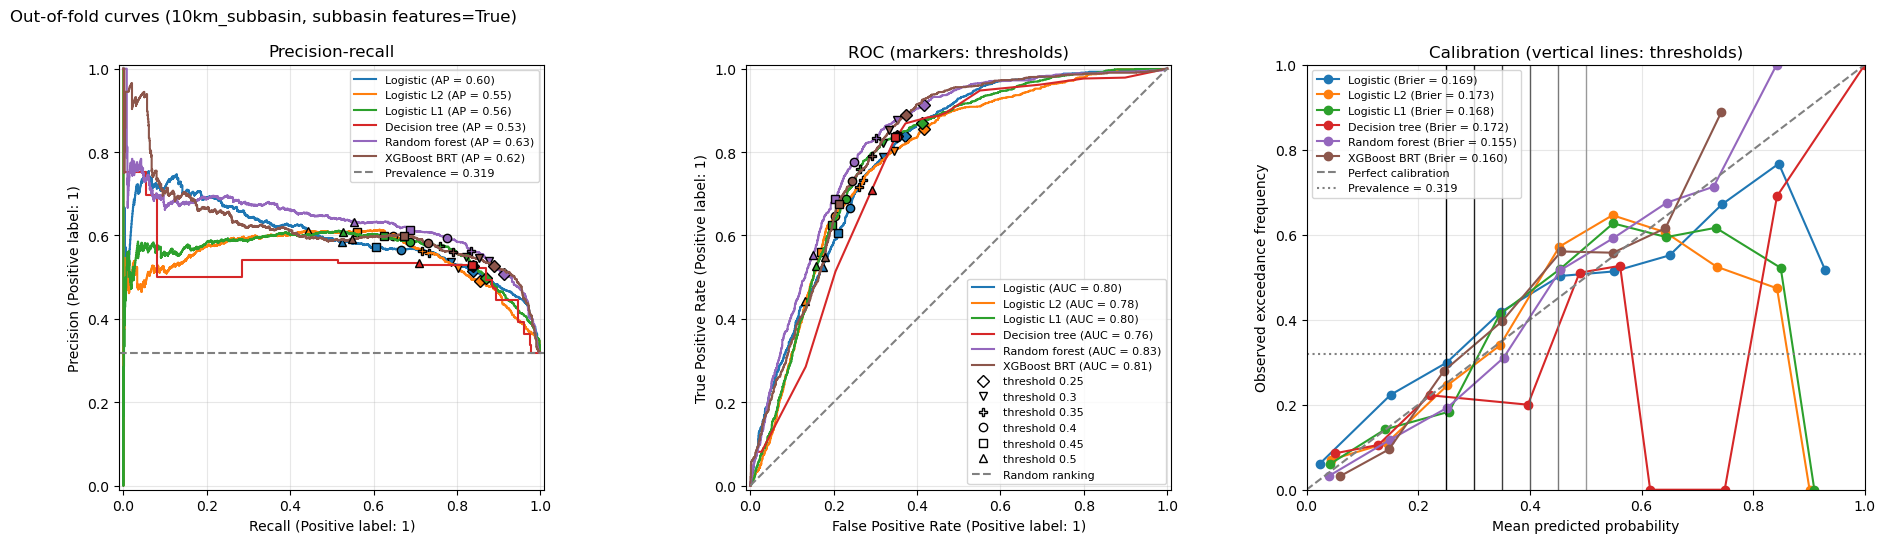

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(19, 5.5))
for name, prob in probs.items():
    PrecisionRecallDisplay.from_predictions(y_true, prob, name=name, ax=axs[0])
    roc = RocCurveDisplay.from_predictions(y_true, prob, name=name, ax=axs[1])
    color = roc.line_.get_color()
    for threshold in THRESHOLDS:                       # mark where each threshold sits on the curves
        counts = threshold_counts(prob, threshold)
        marker = THRESHOLD_MARKERS[threshold]
        axs[0].plot(counts["recall"], counts["precision"], marker, color=color, markeredgecolor="black")
        axs[1].plot(counts["false_positive_rate"], counts["recall"], marker, color=color, markeredgecolor="black")
    observed, predicted = calibration_curve(y_true, prob, n_bins=10, strategy="uniform")
    axs[2].plot(predicted, observed, marker="o", color=color, label=f"{name} (Brier = {brier_score_loss(y_true, prob):.3f})")

for threshold, marker in THRESHOLD_MARKERS.items():
    axs[1].plot([], [], marker, color="white", markeredgecolor="black", label=f"threshold {threshold}")
axs[0].axhline(prevalence, color="gray", linestyle="--", label=f"Prevalence = {prevalence:.3f}")
axs[0].set_title("Precision-recall")
axs[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random ranking")
axs[1].set_title("ROC (markers: thresholds)")
axs[2].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Perfect calibration")
axs[2].axhline(prevalence, color="gray", linestyle=":", label=f"Prevalence = {prevalence:.3f}")
for threshold, color in THRESHOLD_COLORS.items():
    axs[2].axvline(threshold, color=color, linewidth=1)
axs[2].set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted probability", ylabel="Observed exceedance frequency", title="Calibration (vertical lines: thresholds)")
for ax in axs:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.suptitle(f"Out-of-fold curves ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "pr_roc_calibration")
plt.show()


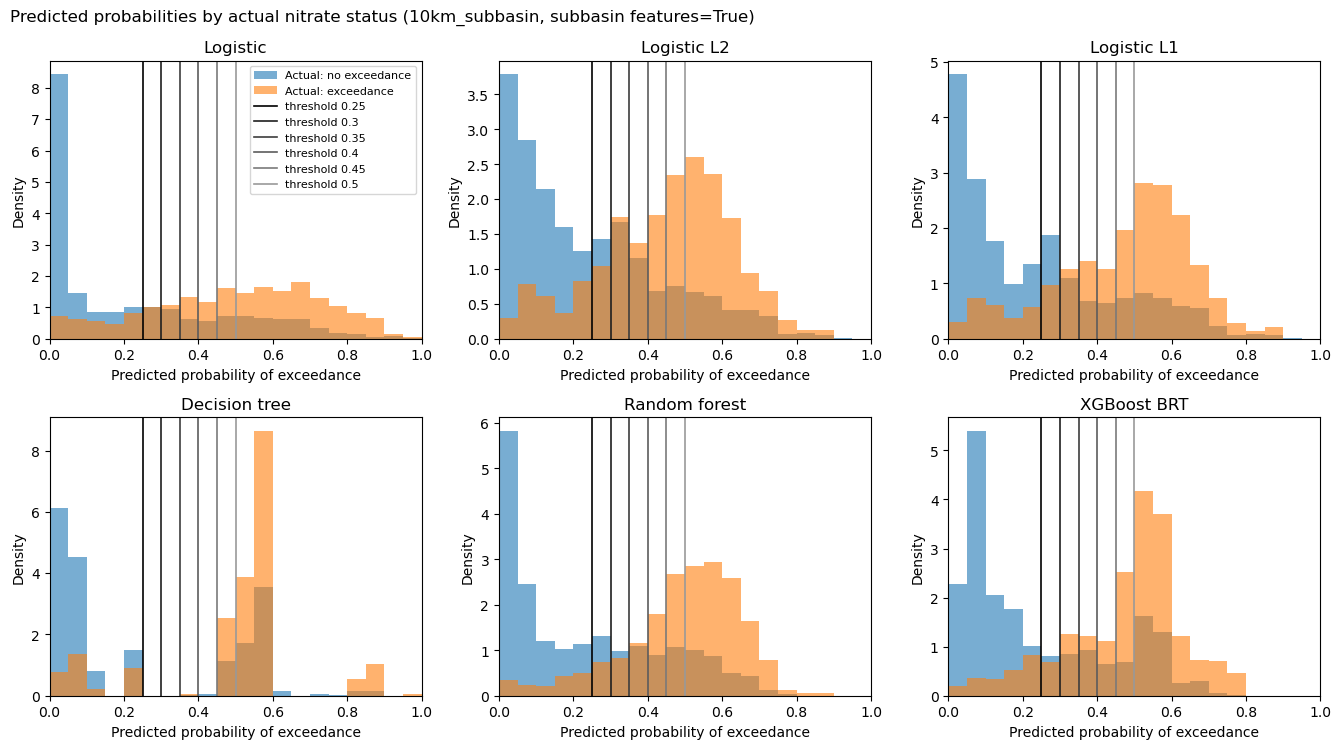

In [14]:
fig, axs = panels(len(probs))
for ax, (name, prob) in zip(axs, probs.items()):
    ax.hist(prob[y_true == 0], bins=20, range=(0, 1), alpha=0.6, density=True, label="Actual: no exceedance")
    ax.hist(prob[y_true == 1], bins=20, range=(0, 1), alpha=0.6, density=True, label="Actual: exceedance")
    for threshold, color in THRESHOLD_COLORS.items():
        ax.axvline(threshold, color=color, linewidth=1.2, label=f"threshold {threshold}")
    ax.set(title=name, xlabel="Predicted probability of exceedance", ylabel="Density", xlim=(0, 1))
axs[0].legend(fontsize=8)
fig.suptitle(f"Predicted probabilities by actual nitrate status ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "probability_distributions")
plt.show()

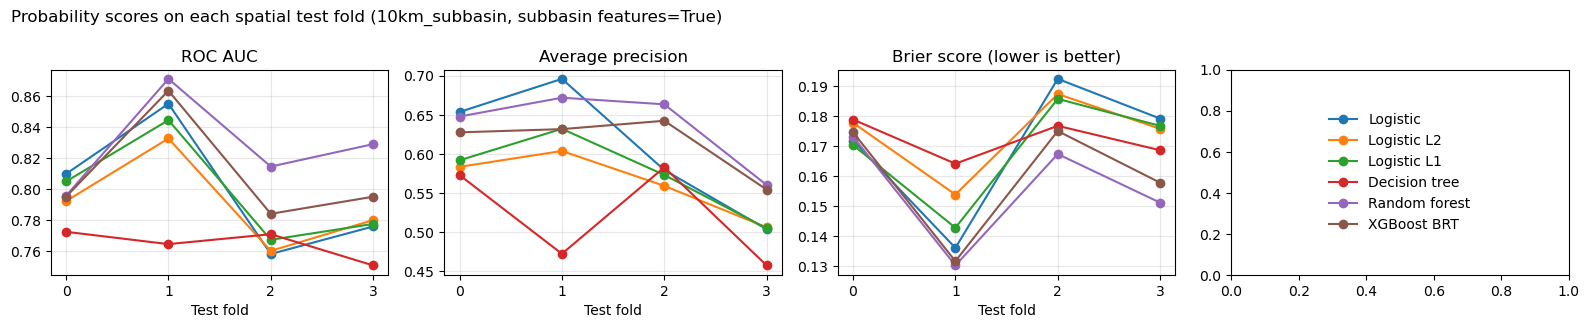

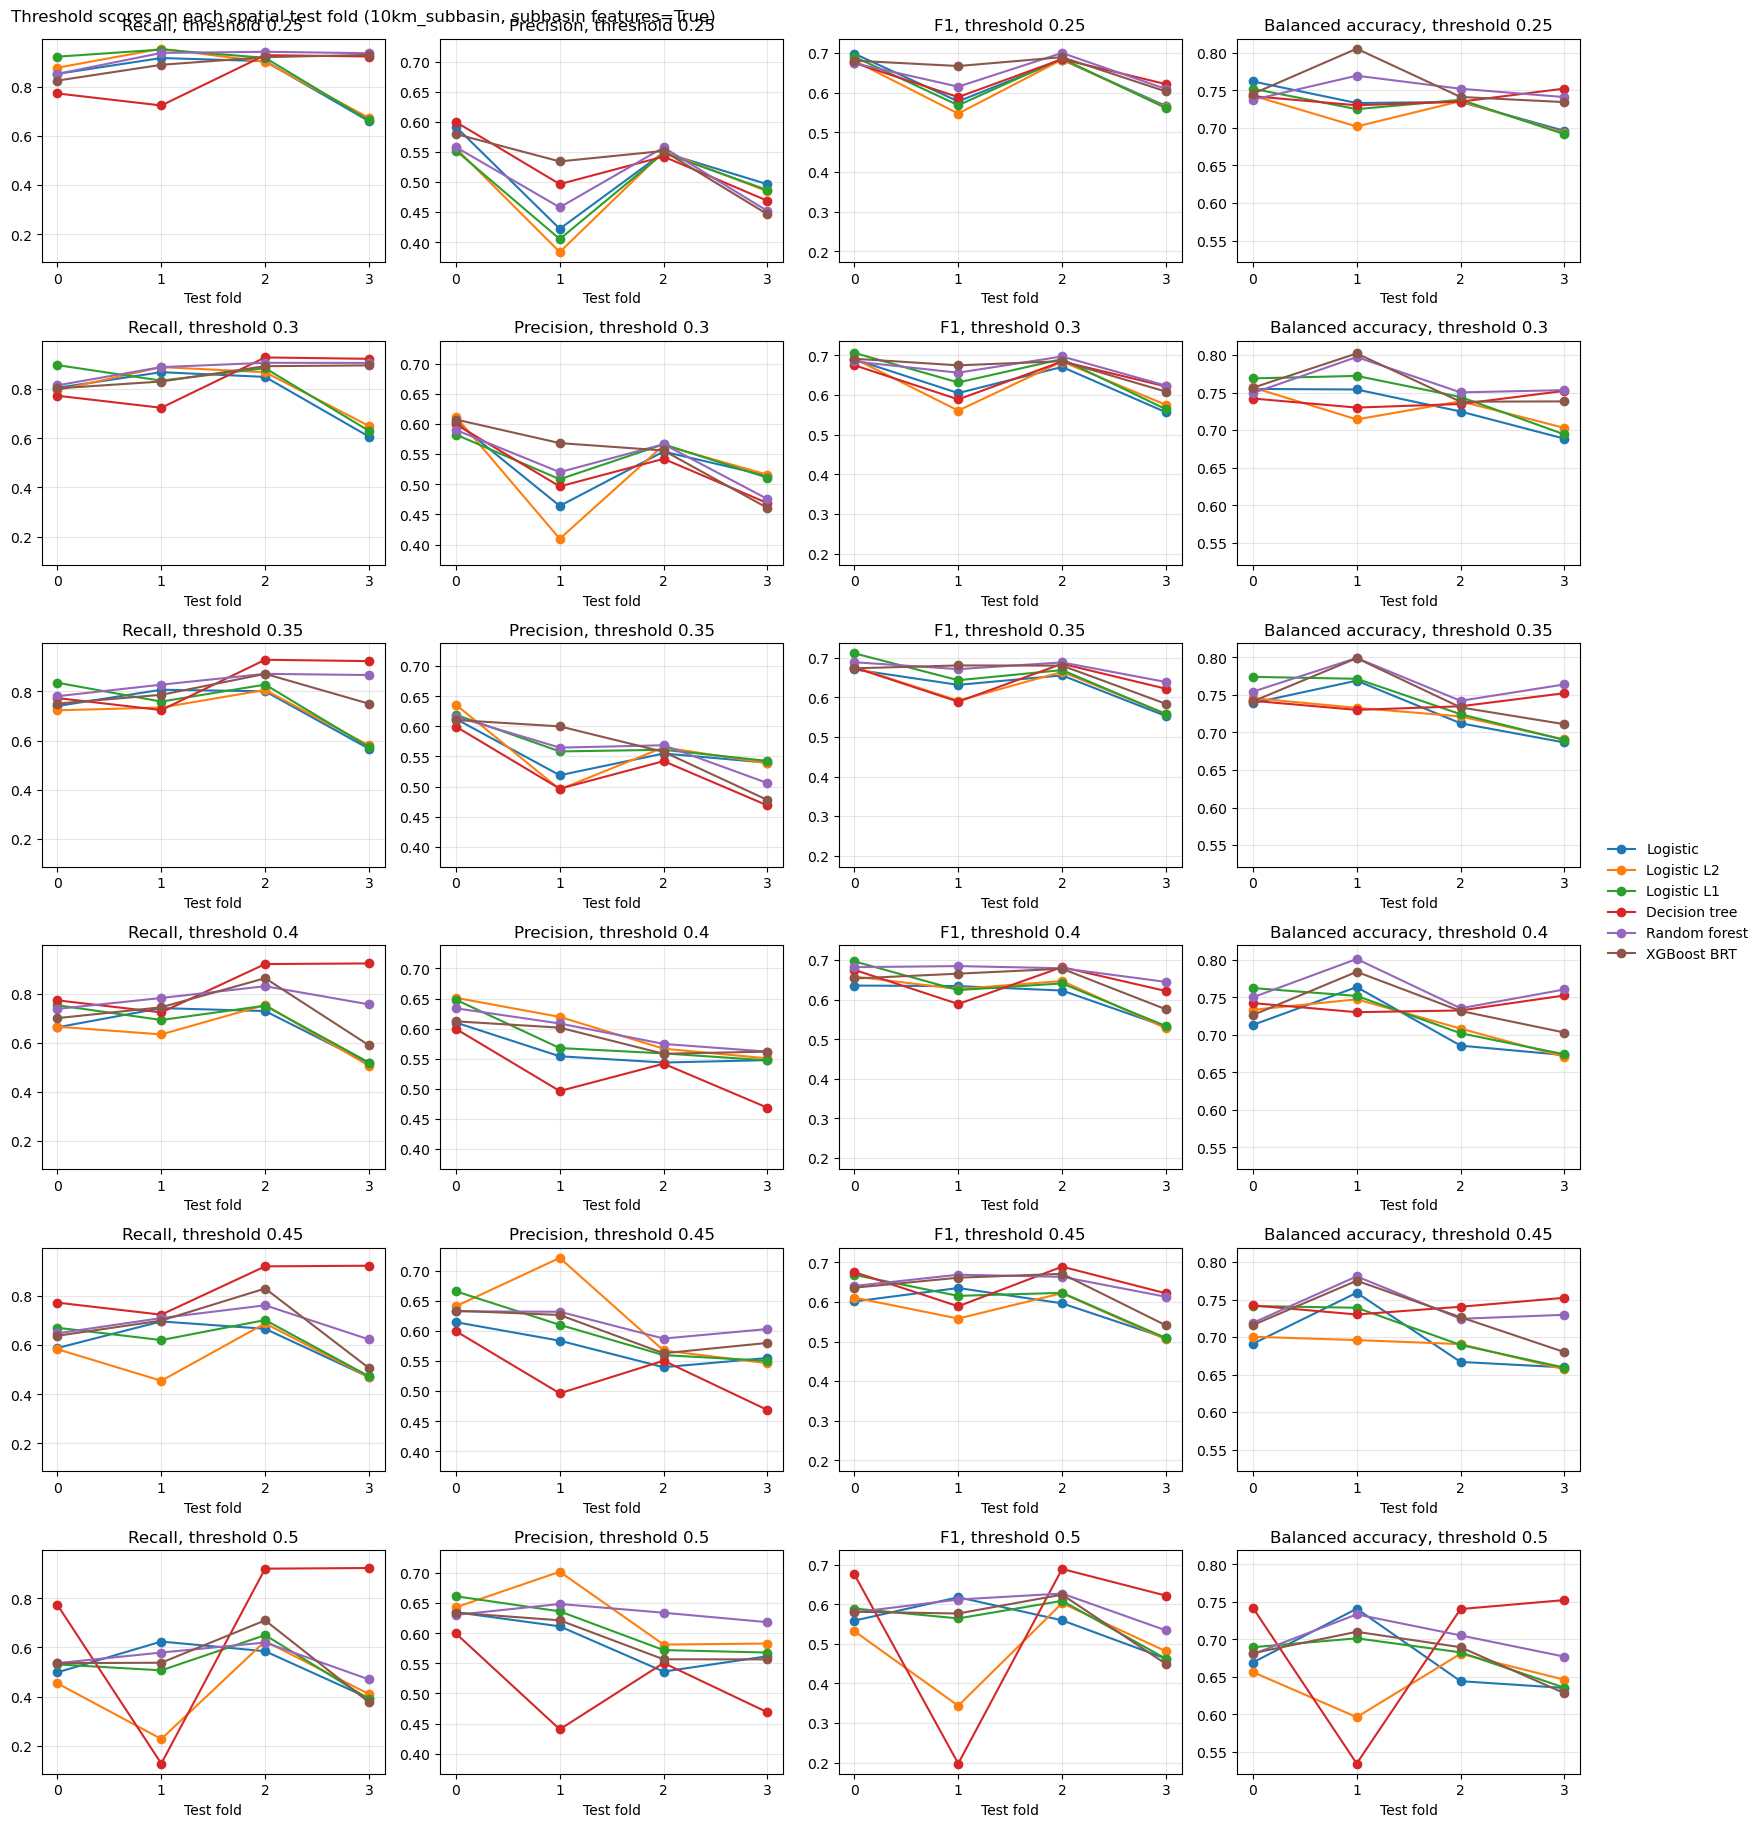

recall  precision     f1  balanced_accuracy
model         threshold                                             
Logistic      0.25        0.834      0.515  0.632              0.731
              0.30        0.783      0.534  0.631              0.731
              0.35        0.729      0.556  0.628              0.727
              0.40        0.663      0.564  0.606              0.709
              0.45        0.605      0.573  0.586              0.694
              0.50        0.525      0.586  0.550              0.672
Logistic L2   0.25        0.852      0.494  0.619              0.718
              0.30        0.801      0.526  0.628              0.728
              0.35        0.711      0.559  0.623              0.723
              0.40        0.640      0.597  0.615              0.715
              0.45        0.549      0.619  0.574              0.686
              0.50        0.429      0.627  0.490              0.645
Logistic L1   0.25        0.864      0.498  0.627              0.727
              0.30        0.812      0.542  0.648              0.745
              0.35        0.749      0.570  0.645              0.740
              0.40        0.679      0.581  0.624              0.723
              0.45        0.617      0.597  0.604              0.707
              0.50        0.520      0.609  0.556              0.677
Decision tree 0.25        0.837      0.527  0.643              0.740
              0.30        0.837      0.527  0.643              0.740
              0.35        0.837      0.527  0.643              0.740
              0.40        0.835      0.527  0.642              0.739
              0.45        0.835      0.529  0.644              0.741
              0.50        0.686      0.515  0.546              0.692
Random forest 0.25        0.918      0.506  0.650              0.750
              0.30        0.880      0.538  0.666              0.763
              0.35        0.837      0.564  0.672              0.765
              0.40        0.777      0.595  0.673              0.762
              0.45        0.686      0.614  0.646              0.738
              0.50        0.551      0.633  0.588              0.699
XGBoost BRT   0.25        0.891      0.528  0.660              0.757
              0.30        0.856      0.548  0.665              0.759
              0.35        0.790      0.561  0.654              0.746
              0.40        0.725      0.584  0.643              0.736
              0.45        0.669      0.601  0.627              0.724
              0.50        0.540      0.592  0.558              0.677

In [15]:
rows = []
for name, prob in probs.items():
    for k in np.unique(folds):
        in_fold = folds == k
        actual, p = y_true[in_fold], prob[in_fold]
        row = {
            "model": name, "fold": k,
            "roc_auc": roc_auc_score(actual, p),
            "average_precision": average_precision_score(actual, p),
            "brier_score": brier_score_loss(actual, p)
        }
        for threshold in THRESHOLDS:
            predicted = (p >= threshold).astype(int)
            rows.append({
                **row, 
                "threshold": threshold,
                "recall": recall_score(actual, predicted, zero_division=0),
                "precision": precision_score(actual, predicted, zero_division=0),
                "f1": f1_score(actual, predicted, zero_division=0),
                "balanced_accuracy": balanced_accuracy_score(actual, predicted)
            })
fold_metrics = pd.DataFrame(rows)

PROBABILITY_METRICS = {
    "roc_auc": "ROC AUC", 
    "average_precision": "Average precision", 
    "brier_score": "Brier score (lower is better)"
}
THRESHOLD_METRICS = {
    "recall": "Recall", 
    "precision": "Precision", 
    "f1": "F1", 
    "balanced_accuracy": "Balanced accuracy"
    }

# Metrics that use the probabilities directly (the same at every threshold)
per_fold = fold_metrics[fold_metrics["threshold"] == THRESHOLDS[0]]
fig, axs = panels(len(PROBABILITY_METRICS) + 1, ncols=4, width=4, height=3.3)
for ax, (metric, title) in zip(axs, PROBABILITY_METRICS.items()):
    for name, group in per_fold.groupby("model", sort=False):
        ax.plot(group["fold"], group[metric], marker="o", label=name)
    ax.set(title=title, xlabel="Test fold", xticks=np.unique(folds))
    ax.grid(alpha=0.3)
handles, labels = axs[0].get_legend_handles_labels()
axs[len(PROBABILITY_METRICS)].legend(handles, labels, loc="center", frameon=False)
fig.suptitle(f"Probability scores on each spatial test fold ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "fold_metrics_probability")
plt.show()

# Metrics that depend on the threshold: one row of panels per threshold
fig, axs = plt.subplots(len(THRESHOLDS), len(THRESHOLD_METRICS), squeeze=False, figsize=(4 * len(THRESHOLD_METRICS), 3.1 * len(THRESHOLDS)), sharey="col")
for row, threshold in zip(axs, THRESHOLDS):
    at_threshold = fold_metrics[fold_metrics["threshold"] == threshold]
    for ax, (metric, title) in zip(row, THRESHOLD_METRICS.items()):
        for name, group in at_threshold.groupby("model", sort=False):
            ax.plot(group["fold"], group[metric], marker="o", label=name)
        ax.set(title=f"{title}, threshold {threshold}", xlabel="Test fold", xticks=np.unique(folds))
        ax.grid(alpha=0.3)
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
fig.suptitle(f"Threshold scores on each spatial test fold ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "fold_metrics_threshold")
plt.show()

fold_metrics.groupby(["model", "threshold"], sort=False)[list(THRESHOLD_METRICS)].mean().round(3)


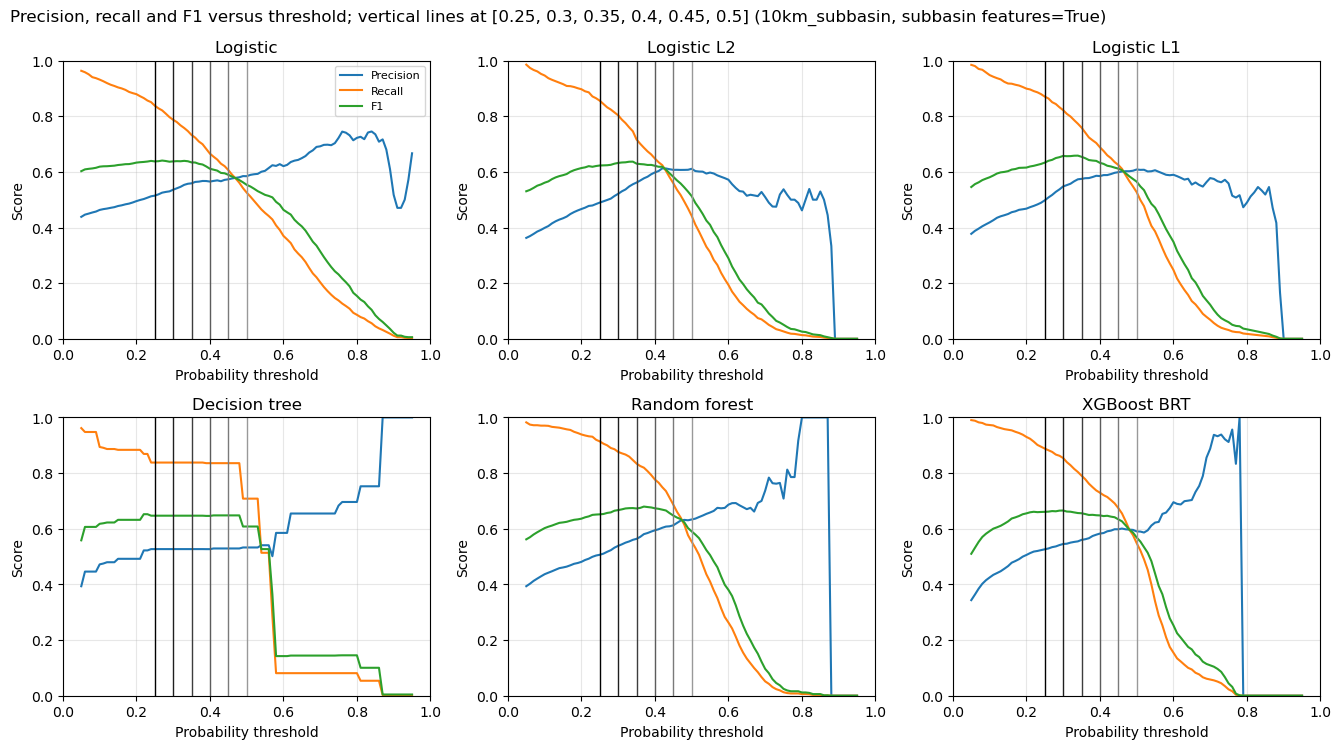

,threshold,precision,recall,f1
model,,,,
Logistic,0.27,0.525,0.821,0.641
Logistic L2,0.34,0.555,0.746,0.637
Logistic L1,0.34,0.573,0.773,0.658
Decision tree,0.22,0.522,0.869,0.652
Random forest,0.37,0.581,0.819,0.680
XGBoost BRT,0.30,0.545,0.854,0.666


In [16]:
thresholds = np.linspace(0.05, 0.95, 91)
fig, axs = panels(len(probs))
best = []
for ax, (name, prob) in zip(axs, probs.items()):
    curve = []
    for t in thresholds:
        predicted = (prob >= t).astype(int)
        curve.append({
            "threshold": t,
            "precision": precision_score(y_true, predicted, zero_division=0),
            "recall": recall_score(y_true, predicted, zero_division=0),
            "f1": f1_score(y_true, predicted, zero_division=0)
        })
    curve = pd.DataFrame(curve)
    for col in ["precision", "recall", "f1"]:
        ax.plot(curve["threshold"], curve[col], label=col.capitalize())
    for threshold, color in THRESHOLD_COLORS.items():
        ax.axvline(threshold, color=color, linewidth=1)
    ax.set(title=name, xlabel="Probability threshold", ylabel="Score", xlim=(0, 1), ylim=(0, 1))
    ax.grid(alpha=0.3)
    best.append({"model": name, **curve.loc[curve["f1"].idxmax()].to_dict()})
axs[0].legend(fontsize=8)
fig.suptitle(f"Precision, recall and F1 versus threshold; vertical lines at {THRESHOLDS} ({TAG})", x=0.01, ha="left")
plt.tight_layout()
save(fig, "threshold_metrics")
plt.show()

pd.DataFrame(best).set_index("model").round(3)      # threshold with the best F1, per model


Note that in the table above, "threshold" refers to the cutoff value that maximizes F1 for each model.

## Choosing a model and a threshold

The goal of this project is to identify areas of potentially high nitrate risk for the sake of public health and to minimize the cost of deploying VTS. Thus, we wish to maximize both recall and precision.

Of all the models, the random forest is the most stable across folds and appears to be the strongest performer overall. We choose our final model to be a random forest classifier, with a threshold of 0.4.

In [17]:
summarize(load_runs()).to_csv(ROOT / "results" / "model_comparison.csv")